In [2]:
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from imblearn.over_sampling import SMOTENC
import pandas as pd
from sklearn.model_selection import train_test_split

In [9]:
# 데이터 불러오기 및 생성
X = pd.read_csv('/content/data/X_features.csv')
y = pd.read_csv('/content/data/y_target.csv').squeeze() # y 는 시리즈형태로 나와야 하므로 squeeze 사용
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)

In [ ]:

# SMOTENC 를 사용하기 위한 원샷 컬럼 지정
categorical_features_idx = [] 
for col in ['material_in', 'shift_주간', 'shift_야간']: # 해당 컬럼명을
    if col in X.columns: # X 컬럼들 중에 있는지 찾아서
        # print(f'{col} : {X.columns.get_loc(col)}')
        categorical_features_idx.append(X.columns.get_loc(col)) # 컬럼인덱스를 넣는다.
print(categorical_features_idx)

[3, 7, 6]


In [5]:
candidates = {}
# LogisticRegression
candidates['LR (기본)'] = Pipeline([('sc', StandardScaler()),('m', LogisticRegression(max_iter=2000))])
candidates['LR (weight)'] = Pipeline([
    ('sc', StandardScaler()),
    ('m', LogisticRegression(max_iter=2000, class_weight='balanced'))
])
candidates['LR (SMOTENC)'] = Pipeline([
    ('sc', StandardScaler()),
    ('smote', SMOTENC(categorical_features=categorical_features_idx, random_state=0)),
    ('m', LogisticRegression(max_iter=2000))
])

In [6]:
# RandomForestClassifier
candidates['RF (기본)'] = Pipeline([('m', RandomForestClassifier(n_estimators=300, random_state=0))])
candidates['RF (weight)'] = Pipeline([
    ('m', RandomForestClassifier(n_estimators=300, random_state=0, class_weight='balanced'))
])
candidates['RF (SMOTENC)'] = Pipeline([
    ('smote', SMOTENC(categorical_features=categorical_features_idx, random_state=0)),
    ('m', RandomForestClassifier(n_estimators=300, random_state=0))
])

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
# f1 : 정밀도(Precision)와 재현율(Recall)의 조화평균
# f1_macro(단순 평균): 모든 클래스의 F1-score를 각각 구한 뒤 똑같이 1/n로 단순 평균을 냄
# f1_weighted(가중 평균): 데이터 개수가 많은 클래스에 더 큰 가중치를 주어 평균을 냄
for name, model in candidates.items():
    s = cross_val_score(model, x_train, y_train, cv=cv, scoring='f1_macro')
    print(f'{name:12s} macro-F1 = {s.mean():.3f} ± {s.std():.3f}')

LR (기본)      macro-F1 = 0.851 ± 0.026
LR (weight)  macro-F1 = 0.817 ± 0.026
LR (SMOTENC) macro-F1 = 0.827 ± 0.027
RF (기본)      macro-F1 = 0.829 ± 0.031
RF (weight)  macro-F1 = 0.830 ± 0.026
RF (SMOTENC) macro-F1 = 0.822 ± 0.027


In [28]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score
import matplotlib.pyplot as plt

# 1 등으로 해야 하지만 그냥 이걸로 해 보자
best = candidates['RF (SMOTENC)'].fit(x_train, y_train)
pred = best.predict(x_test)

In [30]:

# macro-F1 평가
f1_score = f1_score(y_test, pred, average='macro') # 정답과 예측값을 대조헤서 macro 방식으로 F1 추출
print(f'macro-F1 : {f1_score:.3f}')
# 각 부서/유형별로 얼마나 잘 맞히고 있는지 상세 성적표
detail_score = classification_report(y_test, pred, digits=3) # digits=3 <- 소숫점 세자리
print(detail_score) # support : 정답데이터의 수


macro-F1 : 0.797
              precision    recall  f1-score   support

          설비      0.943     0.945     0.944       546
          운영      0.452     0.549     0.496        51
          자재      0.983     0.904     0.942       188
          품질      0.797     0.817     0.807       115

    accuracy                          0.898       900
   macro avg      0.794     0.804     0.797       900
weighted avg      0.905     0.898     0.901       900



In [ ]:
# 혼동행렬
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=['설비', '자재', '품질', '운영'],
                                        normalize='true', values_format='.2f')
plt.title('Confusion Matrix (row-normalized)')
plt.xticks(ticks=[0,1,2,3],labels=['Eq', 'Mat', 'Q', 'Oper'], rotation=0)
plt.yticks(ticks=[0,1,2,3],labels=['Eq', 'Mat', 'Q', 'Oper'], rotation=0)
plt.show()

            건수   총정지(분)    평균정지(분)  누적비율(%)
pred_type                                  
설비         547  15798.1  28.881353     69.6
자재         173   3810.9  22.028324     86.3
품질         118   1853.1  15.704237     94.5
운영          62   1247.5  20.120968    100.0


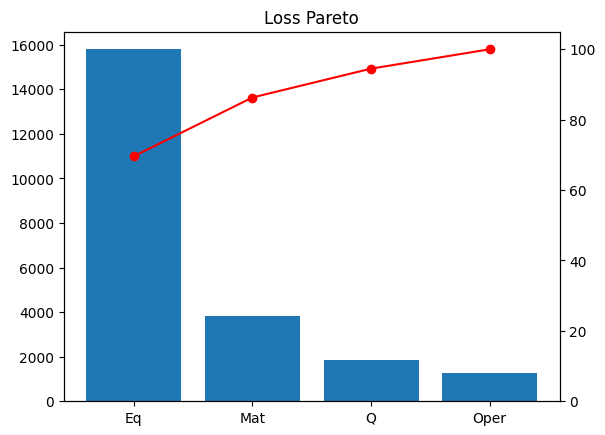

ng_cnt         0.260378
alarm_cnt      0.176903
wip_buffer     0.173211
material_in    0.168847
equip_temp     0.133817
prev_ct        0.077486
shift_주간       0.004894
shift_야간       0.004464
dtype: float64


In [29]:
df = pd.read_csv('/content/data/stop_events.csv')
report = df.loc[x_test.index, ['duration']].copy()
report['pred_type'] = pred

summary = (report.groupby('pred_type')['duration']
                 .agg(['count', 'sum', 'mean'])
                 .rename(columns={'count': '건수', 'sum': '총정지(분)', 'mean': '평균정지(분)'})
                 .sort_values('총정지(분)', ascending=False))
summary['누적비율(%)'] = (summary['총정지(분)'].cumsum() / summary['총정지(분)'].sum() * 100).round(1)
print(summary)       # → 로스 현황판

# 파레토 차트
fig, ax = plt.subplots()
ax.bar(summary.index, summary['총정지(분)'])
ax2 = ax.twinx()
ax2.plot(summary.index, summary['누적비율(%)'], 'r-o')
ax2.set_ylim(0, 105)
plt.title('Loss Pareto')
plt.xticks(ticks=[0,1,2,3],labels=['Eq', 'Mat', 'Q', 'Oper'], rotation=0)
plt.show()

# 분류 근거 : 특징 중요도
rf = best.named_steps['m']
print(pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False))